# Comparison of Baseline and Preprocessed ResNet18 Models

This notebook compares the original binary `ResNet18` baseline against the preprocessing-enhanced `ResNet18` experiment.
The goal is to quantify the trade-off between overall classification performance and clinically important error behavior.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from torch.utils.data import DataLoader

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [2]:
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "src"))

from dr_detection.config import load_yaml_config, resolve_path
from dr_detection.dataset import FundusImageDataset, default_transforms, load_fundus_records
from dr_detection.train import build_model

comparison_dir = project_root / "outputs" / "comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

model_specs = [
    {
        "display_name": "Baseline ResNet18",
        "short_name": "baseline",
        "config_path": project_root / "configs" / "default.yaml",
        "checkpoint_path": project_root / "models" / "best_model.pt",
    },
    {
        "display_name": "Preprocessed ResNet18",
        "short_name": "preprocessed",
        "config_path": project_root / "configs" / "resnet18_preprocessed.yaml",
        "checkpoint_path": project_root / "models" / "resnet18_preprocessed" / "best_model.pt",
    },
]

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Device: {device}")
print(f"Output directory: {comparison_dir}")


Device: mps
Output directory: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/outputs/comparison


In [3]:
def evaluate_model(spec: dict) -> tuple[dict, pd.DataFrame, dict]:
    config = load_yaml_config(spec["config_path"])
    dataset_cfg = config["dataset"]
    training_cfg = config["training"]

    test_records = load_fundus_records(
        csv_path=resolve_path(project_root, dataset_cfg["test_csv_path"]),
        images_dir=resolve_path(project_root, dataset_cfg["test_images_dir"]),
        image_extension=dataset_cfg.get("image_extension", ".png"),
        binary_classification=dataset_cfg.get("binary_classification", True),
    )

    test_dataset = FundusImageDataset(
        test_records,
        transform=default_transforms(
            image_size=dataset_cfg.get("image_size", 224),
            train=False,
            preprocessing_cfg=dataset_cfg.get("preprocessing"),
        ),
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=training_cfg.get("batch_size", 16),
        shuffle=False,
        num_workers=0,
    )

    checkpoint = torch.load(spec["checkpoint_path"], map_location=device)
    model = build_model(
        model_name=checkpoint["model_name"],
        num_classes=checkpoint["num_classes"],
        pretrained=False,
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(device)
    model.eval()

    labels = []
    predictions = []
    scores = []
    image_paths = []

    with torch.no_grad():
        for images, batch_labels, batch_paths in test_loader:
            images = images.to(device)
            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)
            batch_predictions = probabilities.argmax(dim=1)

            labels.extend(batch_labels.tolist())
            predictions.extend(batch_predictions.cpu().tolist())
            scores.extend(probabilities[:, 1].cpu().tolist())
            image_paths.extend(batch_paths)

    cm = confusion_matrix(labels, predictions)
    tn, fp, fn, tp = cm.ravel()
    fpr, tpr, _ = roc_curve(labels, scores)

    metrics = {
        "model": spec["display_name"],
        "short_name": spec["short_name"],
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1_score": f1_score(labels, predictions, zero_division=0),
        "roc_auc": roc_auc_score(labels, scores),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

    predictions_df = pd.DataFrame(
        {
            "image_path": image_paths,
            "true_label": labels,
            "predicted_label": predictions,
            "dr_probability": scores,
        }
    )
    predictions_df["correct"] = predictions_df["true_label"] == predictions_df["predicted_label"]
    predictions_df["model"] = spec["short_name"]

    roc_data = {
        "fpr": fpr,
        "tpr": tpr,
        "roc_auc": metrics["roc_auc"],
    }
    return metrics, predictions_df, roc_data


In [4]:
results = {}
for spec in model_specs:
    metrics, predictions_df, roc_data = evaluate_model(spec)
    results[spec["short_name"]] = {
        "metrics": metrics,
        "predictions": predictions_df,
        "roc": roc_data,
    }

baseline_predictions = results["baseline"]["predictions"]
preprocessed_predictions = results["preprocessed"]["predictions"]

comparison_predictions = baseline_predictions.merge(
    preprocessed_predictions[["image_path", "predicted_label", "dr_probability", "correct"]],
    on="image_path",
    suffixes=("_baseline", "_preprocessed"),
)

change_summary_df = pd.DataFrame(
    {
        "category": [
            "Errors fixed by preprocessing",
            "New errors introduced by preprocessing",
            "Wrong in both models",
            "Correct in both models",
            "False Positive -> True Negative",
            "False Negative -> True Positive",
            "True Positive -> False Negative",
            "True Negative -> False Positive",
        ],
        "count": [
            int((~comparison_predictions["correct_baseline"] & comparison_predictions["correct_preprocessed"]).sum()),
            int((comparison_predictions["correct_baseline"] & ~comparison_predictions["correct_preprocessed"]).sum()),
            int((~comparison_predictions["correct_baseline"] & ~comparison_predictions["correct_preprocessed"]).sum()),
            int((comparison_predictions["correct_baseline"] & comparison_predictions["correct_preprocessed"]).sum()),
            int(((comparison_predictions["true_label"] == 0) & (comparison_predictions["predicted_label_baseline"] == 1) & (comparison_predictions["predicted_label_preprocessed"] == 0)).sum()),
            int(((comparison_predictions["true_label"] == 1) & (comparison_predictions["predicted_label_baseline"] == 0) & (comparison_predictions["predicted_label_preprocessed"] == 1)).sum()),
            int(((comparison_predictions["true_label"] == 1) & (comparison_predictions["predicted_label_baseline"] == 1) & (comparison_predictions["predicted_label_preprocessed"] == 0)).sum()),
            int(((comparison_predictions["true_label"] == 0) & (comparison_predictions["predicted_label_baseline"] == 0) & (comparison_predictions["predicted_label_preprocessed"] == 1)).sum()),
        ],
    }
)

print(pd.DataFrame([results["baseline"]["metrics"], results["preprocessed"]["metrics"]]))


                   model    short_name  accuracy  precision    recall  \
0      Baseline ResNet18      baseline  0.978142   0.964912  0.988024   
1  Preprocessed ResNet18  preprocessed  0.980874   0.981928  0.976048   

   f1_score   roc_auc  true_negative  false_positive  false_negative  \
0  0.976331  0.997352            193               6               2   
1  0.978979  0.997111            196               3               4   

   true_positive  
0            165  
1            163  


**Table 4.1. Comparison of final test-set metrics between the baseline and preprocessing-enhanced ResNet18 models**


In [5]:
metric_names = ["accuracy", "precision", "recall", "f1_score", "roc_auc"]
metrics_comparison_df = pd.DataFrame(
    {
        "metric": metric_names,
        "baseline_resnet18": [results["baseline"]["metrics"][metric] for metric in metric_names],
        "preprocessed_resnet18": [results["preprocessed"]["metrics"][metric] for metric in metric_names],
    }
)
metrics_comparison_df["delta_preprocessed_minus_baseline"] = (
    metrics_comparison_df["preprocessed_resnet18"] - metrics_comparison_df["baseline_resnet18"]
)
metrics_comparison_df[["baseline_resnet18", "preprocessed_resnet18", "delta_preprocessed_minus_baseline"]] = metrics_comparison_df[["baseline_resnet18", "preprocessed_resnet18", "delta_preprocessed_minus_baseline"]].round(4)

metrics_comparison_df.to_csv(comparison_dir / "table_4_1_model_metrics_comparison.csv", index=False)
metrics_comparison_df


,metric,baseline_resnet18,preprocessed_resnet18,delta_preprocessed_minus_baseline
0,accuracy,0.9781,0.9809,0.0027
1,precision,0.9649,0.9819,0.0170
2,recall,0.9880,0.9760,-0.0120
3,f1_score,0.9763,0.9790,0.0026
4,roc_auc,0.9974,0.9971,-0.0002


**Table 4.2. Comparison of confusion-matrix counts between the two ResNet18 experiments**


In [6]:
outcome_rows = [
    ("True Negative", "true_negative"),
    ("False Positive", "false_positive"),
    ("False Negative", "false_negative"),
    ("True Positive", "true_positive"),
]
confusion_comparison_df = pd.DataFrame(
    {
        "outcome": [label for label, _ in outcome_rows],
        "baseline_resnet18": [results["baseline"]["metrics"][key] for _, key in outcome_rows],
        "preprocessed_resnet18": [results["preprocessed"]["metrics"][key] for _, key in outcome_rows],
    }
)
confusion_comparison_df["delta_preprocessed_minus_baseline"] = (
    confusion_comparison_df["preprocessed_resnet18"] - confusion_comparison_df["baseline_resnet18"]
)

confusion_comparison_df.to_csv(comparison_dir / "table_4_2_confusion_count_comparison.csv", index=False)
confusion_comparison_df


,outcome,baseline_resnet18,preprocessed_resnet18,delta_preprocessed_minus_baseline
0,True Negative,193,196,3
1,False Positive,6,3,-3
2,False Negative,2,4,2
3,True Positive,165,163,-2


**Table 4.3. Prediction-change summary after adding preprocessing to the ResNet18 pipeline**


In [7]:
change_summary_df.to_csv(comparison_dir / "table_4_3_prediction_change_summary.csv", index=False)
change_summary_df


,category,count
0,Errors fixed by preprocessing,4
1,New errors introduced by preprocessing,3
2,Wrong in both models,4
3,Correct in both models,355
4,False Positive -> True Negative,3
5,False Negative -> True Positive,1
6,True Positive -> False Negative,3
7,True Negative -> False Positive,0


**Figure 4.1. Comparison of core test metrics between the baseline and preprocessing-enhanced ResNet18 models**


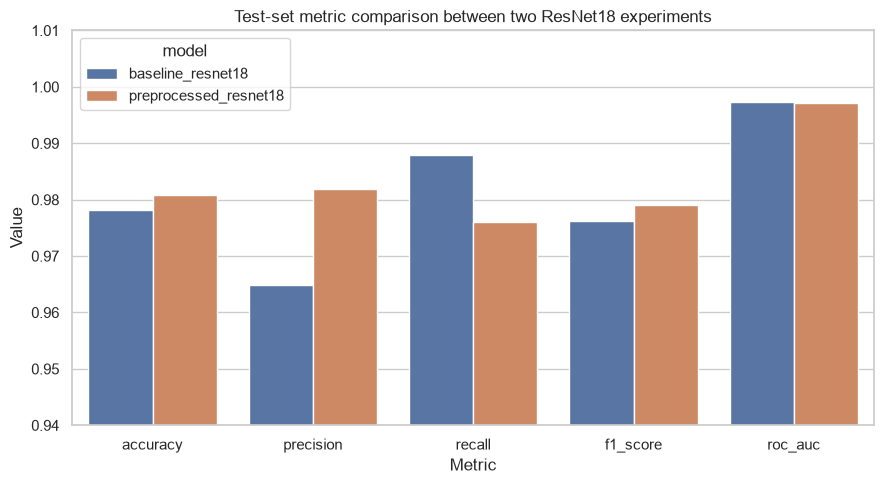

In [8]:
plot_df = metrics_comparison_df.melt(
    id_vars="metric",
    value_vars=["baseline_resnet18", "preprocessed_resnet18"],
    var_name="model",
    value_name="value",
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=plot_df, x="metric", y="value", hue="model", ax=ax)
ax.set_title("Test-set metric comparison between two ResNet18 experiments")
ax.set_xlabel("Metric")
ax.set_ylabel("Value")
ax.set_ylim(0.94, 1.01)
plt.tight_layout()
fig.savefig(comparison_dir / "figure_4_1_metric_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 4.2. False-positive and false-negative trade-off between the two ResNet18 experiments**


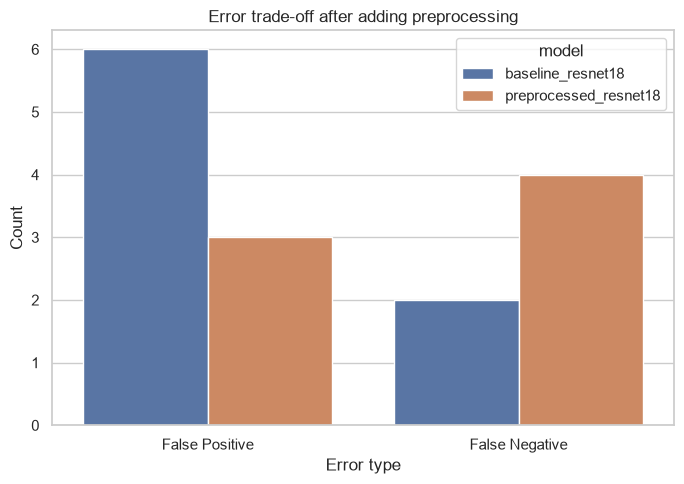

In [9]:
error_tradeoff_df = confusion_comparison_df.loc[
    confusion_comparison_df["outcome"].isin(["False Positive", "False Negative"])
].melt(
    id_vars="outcome",
    value_vars=["baseline_resnet18", "preprocessed_resnet18"],
    var_name="model",
    value_name="count",
)

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=error_tradeoff_df, x="outcome", y="count", hue="model", ax=ax)
ax.set_title("Error trade-off after adding preprocessing")
ax.set_xlabel("Error type")
ax.set_ylabel("Count")
plt.tight_layout()
fig.savefig(comparison_dir / "figure_4_2_error_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 4.3. ROC-curve comparison between the baseline and preprocessing-enhanced ResNet18 models**


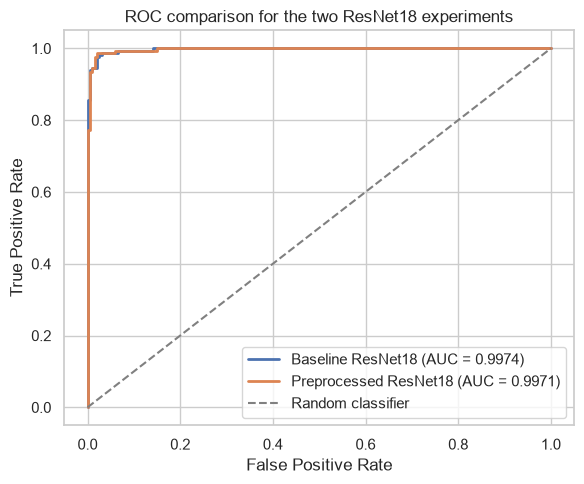

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(
    results["baseline"]["roc"]["fpr"],
    results["baseline"]["roc"]["tpr"],
    linewidth=2,
    label=f"Baseline ResNet18 (AUC = {results['baseline']['roc']['roc_auc']:.4f})",
)
ax.plot(
    results["preprocessed"]["roc"]["fpr"],
    results["preprocessed"]["roc"]["tpr"],
    linewidth=2,
    label=f"Preprocessed ResNet18 (AUC = {results['preprocessed']['roc']['roc_auc']:.4f})",
)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set_title("ROC comparison for the two ResNet18 experiments")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(comparison_dir / "figure_4_3_roc_curve_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
